In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

### Fit

In [ ]:
from raddest.api.flowvi import FlowVI

In [ ]:
flow_vi = FlowVI(x_min=max(0, x_obs.min()),
                 x_max=x_obs.max(),
                 x_err_min=x_err.min() * 0.8,
                 x_err_max=x_err.max() * 1.2)

2026-11-24 20:44:16.927517: W external/xla/xla/service/gpu/nvptx_compiler.cc:765] The NVIDIA driver's CUDA version is 12.4 which is older than the ptxas CUDA version (12.6.77). Because the driver is older than the ptxas version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.


In [ ]:
flow_vi.fit(x_obs,
            x_err,
            n_pre=1000,
            n_train=10_000,
            n_node=51,
            verbose=True,
            check_per_step=10,
            early_stop=True,
            max_stuck=5,
            stuck_frac=0.01,
            guess_method='auto',
            skip_fitting_if_init_good=False)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 1/1000 [00:05<1:38:55,  5.94s/it]

  1%|          | 8/1000 [00:06<09:10,  1.80it/s]  

  2%|▏         | 15/1000 [00:06<04:06,  3.99it/s]

  2%|▏         | 22/1000 [00:06<02:22,  6.88it/s]

  3%|▎         | 29/1000 [00:06<01:31, 10.57it/s]

... (144 outputs left out)

step 90: loss 2.1857223510742188


step 100: loss 2.178643226623535


step 110: loss 2.1730895042419434


step 120: loss 2.166980028152466


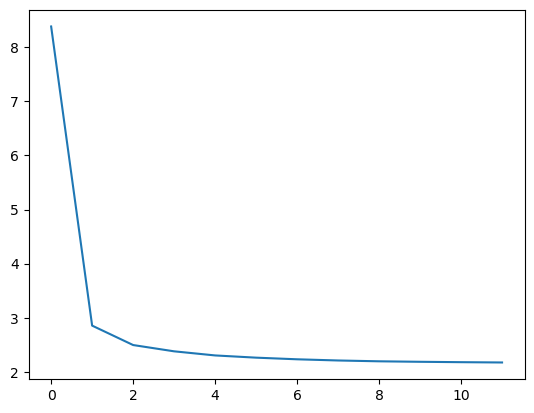

In [ ]:
plt.plot(flow_vi.loss)

In [ ]:
x_gen, x_err_gen, x_obs_gen = flow_vi.sample(10000, return_numpy=True)

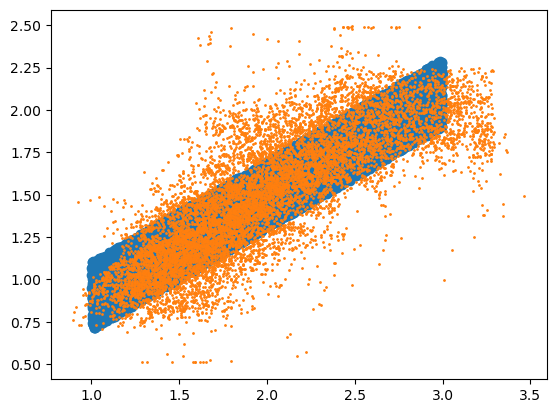

In [ ]:
plt.scatter(x, x_err)
plt.scatter(x_gen, x_err_gen, s=1)

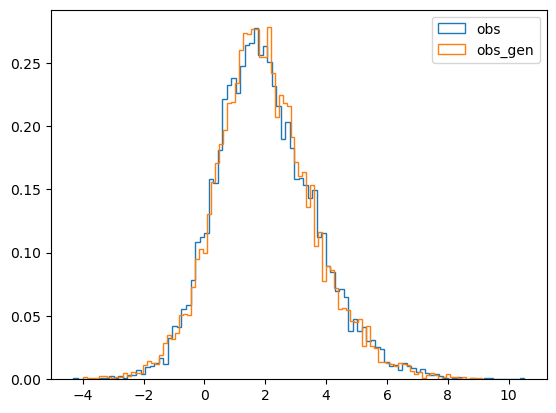

In [ ]:
plt.hist(x_obs, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

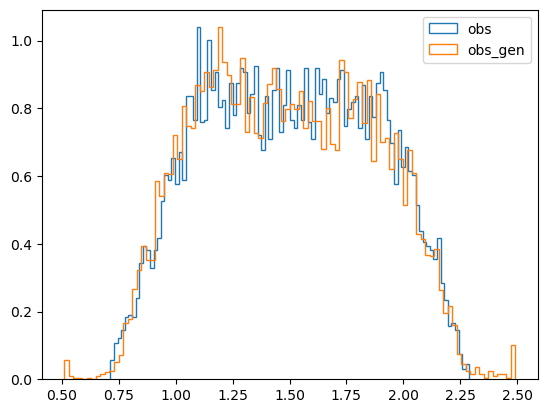

In [ ]:
plt.hist(x_err, bins=100, histtype='step', density=True, label='obs');
plt.hist(x_err_gen, bins=100, histtype='step', density=True, label='obs_gen');
plt.legend()

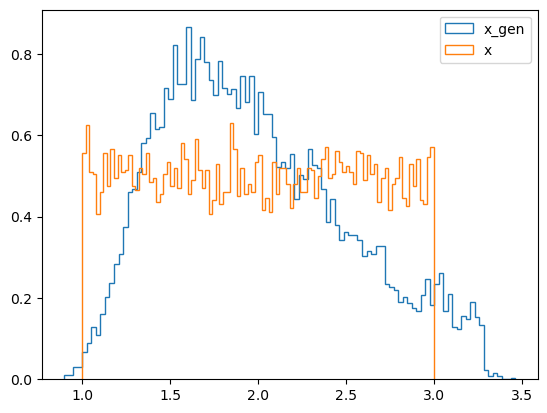

In [ ]:
plt.hist(x_gen, bins=100, histtype='step', density=True, label='x_gen');
plt.hist(x, bins=100, histtype='step', density=True, label='x');
plt.legend()

In [ ]:
flow_vi.ks_test(x_obs, x_err, N=10000)

(0.0375000461935997, 0.00017885814928449807)

In [ ]:
D_lst, p_lst = flow_vi.ks_test(x_obs, x_err, N=10000, K=100, M=10000)

In [ ]:
10**np.mean(np.log10(p_lst))

0.00014765571504371655

/home/jingtao/software/anaconda3/envs/raddest/lib/python3.9/pty.py:85: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  pid, fd = os.forkpty()


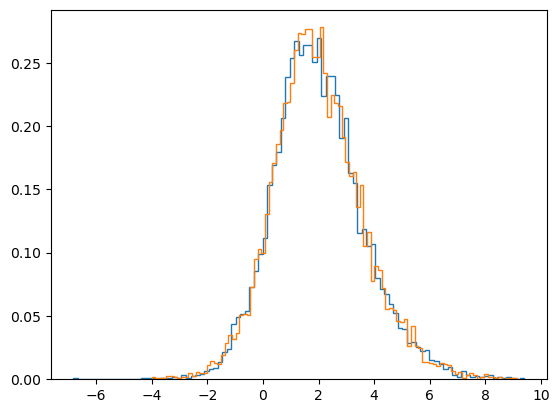

In [ ]:
! rm -rf test

flow_vi.save('test')
flow_loaded = FlowVI.load('test')

x_gen_load, x_err_gen_load, x_obs_gen_load = flow_loaded.sample(10000, x_min=0, x_max=x_obs.max(), x_err_min=0,
                   x_err_max=x_err.max() * 1.2, return_numpy=True)

plt.hist(x_obs_gen_load, bins=100, histtype='step', density=True, label='obs_gen_load');
plt.hist(x_obs_gen, bins=100, histtype='step', density=True, label='obs_gen');

# remove the folder
! rm -rf test

### Guess

We can heuristically "guess" the intrinsic value and then pre-train the NF model on this guessed value to get a good starting point for the optimization. This approach is automatically implemented in the `FlowVI.fit` method. 

Here we show an example of guessed x - x_err correlation.

In [ ]:
from raddest.shrink import shrink_data

In [ ]:
x = np.random.uniform(1, 3, size=10000)
x_err = np.random.uniform(0.1, 0.5, size=10000) + x * 0.6
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

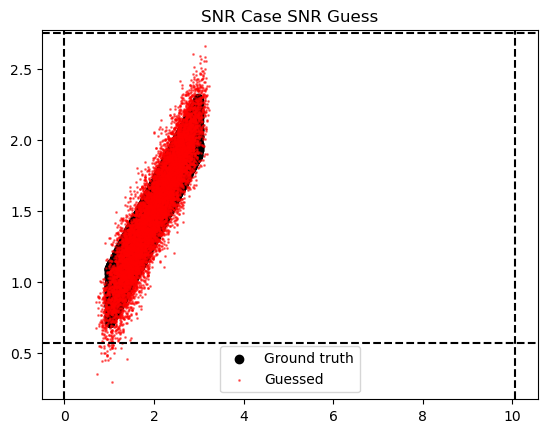

In [ ]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='SNR',
                                     to_recalibrate=False)
plt.title('SNR Case SNR Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

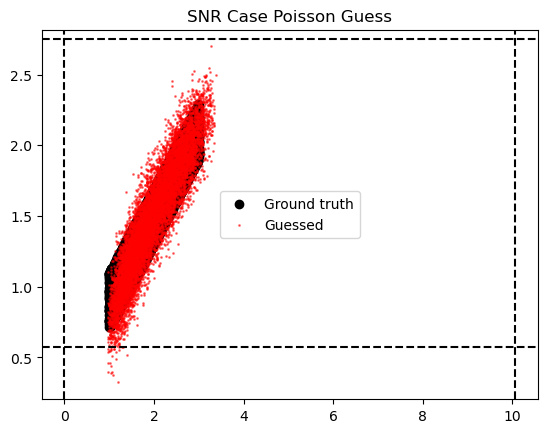

In [ ]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='poisson',
                                     to_recalibrate=True)
plt.title('SNR Case Poisson Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

In [ ]:
x = np.random.uniform(1, 3, size=10000) # S_x ~ 0.576
x_err = np.random.uniform(0.1, 0.5, size=10000) + np.sqrt(x) * 0.6 # sigma ~ 0.115 
x_obs = np.random.normal(x, x_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)

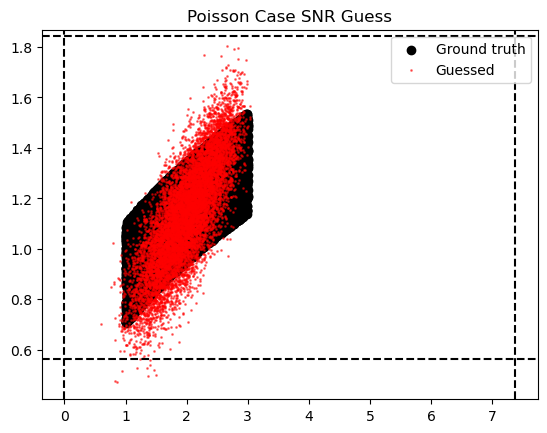

In [ ]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='SNR',
                                     to_recalibrate=False)
plt.title('Poisson Case SNR Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')

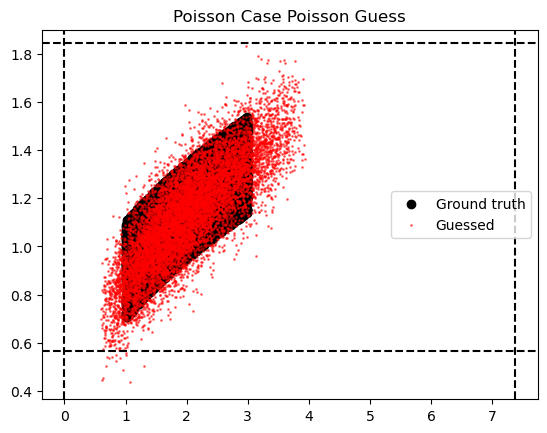

In [ ]:
x_shrink, x_err_shrink = shrink_data(x_obs,
                                     x_err,
                                     verbose=True,
                                     method='poisson',
                                     to_recalibrate=False)
plt.title('Poisson Case Poisson Guess')
plt.scatter(x, x_err, marker='o', color='black', label='Ground truth')
plt.scatter(x_shrink,
            x_err_shrink,
            marker='o',
            color='red',
            label='Guessed',
            s=1,
            alpha=0.5)

plt.axvline(max(0, x_obs.min()), color='black', linestyle='--')
plt.axvline(x_obs.max(), color='black', linestyle='--')
plt.axhline(x_err.min() * 0.8, color='black', linestyle='--')
plt.axhline(x_err.max() * 1.2, color='black', linestyle='--')

plt.legend(loc='best')